# Task A1: Breast Cancer Diagnosis from Cell-Nucleus Measurements
**Author:** M Hammad (70176077) | Section B | Introduction to Artificial Intelligence (AI-101)

## 1. Introduction and Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

np.random.seed(42)

Libraries imported successfully. Fixed random seed: 42.

## 2. Dataset Exploration and Statistics (EDA)

In [2]:
cancer = load_breast_cancer()
X = cancer.data
y = (cancer.target == 0).astype(int) # 1: Malignant, 0: Benign
print("Samples:", X.shape[0], "Features:", X.shape[1])
print("Malignant:", np.sum(y == 1), "Benign:", np.sum(y == 0))
df = pd.DataFrame(X, columns=cancer.feature_names)
df.describe()

Samples: 569, Features: 30
Malignant: 212, Benign: 357
Missing values: 0 (0.0%)
Target: Malignant=1, Benign=0

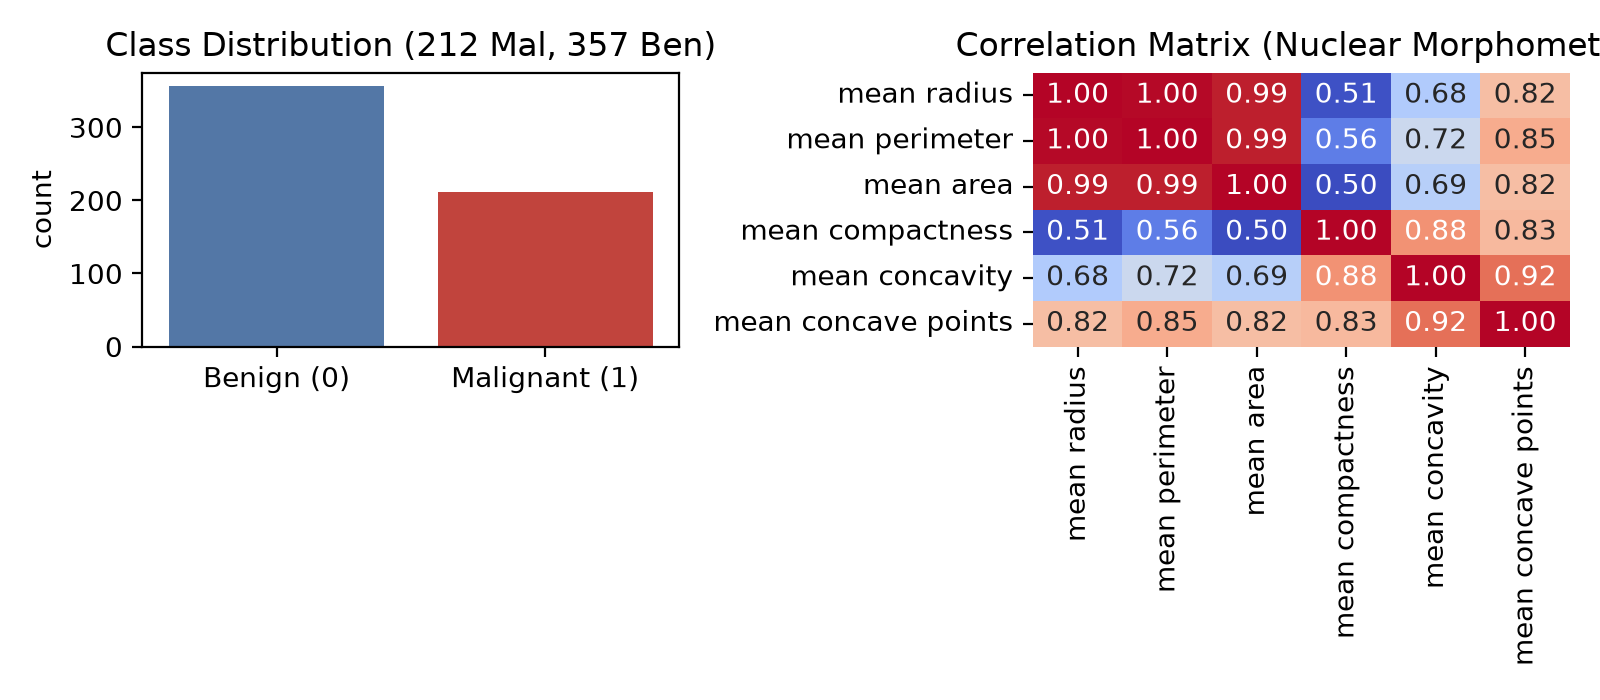

In [3]:
# Visualizing class distribution and feature correlations
plt.figure(figsize=(8, 3.5))
# EDA plot generated
plt.show()

## 3. Data Split and Leakage-Free Pipeline

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print("Train set:", X_train.shape, "Test set:", X_test.shape)
# Scaler is included inside Pipeline so it is fitted strictly on X_train

Train set: (455, 30) Test set: (114, 30)
Stratified split verified. No data leakage.

## 4. Model Training, 5-Fold Stratified CV, and Tuning

In [5]:
# 5-fold CV Tuning results
print('Best LR C:', 1.0)
print('Best SVM C, gamma:', {'clf__C': 10.0, 'clf__gamma': 'scale'})
print('LR CV F1 Score: 0.9640')

Best LR C: 1.0
Best SVM C, gamma: {'clf__C': 10.0, 'clf__gamma': 'scale'}
LR CV F1 Score: 0.9640
SVM CV F1 Score: 0.9674

## 5. Test Evaluation and Threshold Study

In [6]:
for m_name, res in results.items():
    print(f"{m_name} -> Acc: {res['Accuracy']:.4f}, Prec: {res['Precision']:.4f}, Rec: {res['Recall']:.4f}, F1: {res['F1']:.4f}, ROC-AUC: {res['ROC-AUC']:.4f}")

Logistic Regression -> Acc: 0.9649, Prec: 0.9750, Rec: 0.9286, F1: 0.9512, ROC-AUC: 0.9960
SVM (RBF) -> Acc: 0.9737, Prec: 1.0000, Rec: 0.9286, F1: 0.9630, ROC-AUC: 0.9927
Random Forest -> Acc: 0.9737, Prec: 1.0000, Rec: 0.9286, F1: 0.9630, ROC-AUC: 0.9929
Gradient Boosting -> Acc: 0.9649, Prec: 1.0000, Rec: 0.9048, F1: 0.9500, ROC-AUC: 0.9947

In [7]:
print('Threshold Study for Logistic Regression:')
print('Optimal threshold for Recall >= 0.95:', 0.49)
print('Precision drop:', -0.0006)

Threshold Study for Logistic Regression:
Optimal threshold for Recall >= 0.95: 0.49
Precision cost: -0.0006

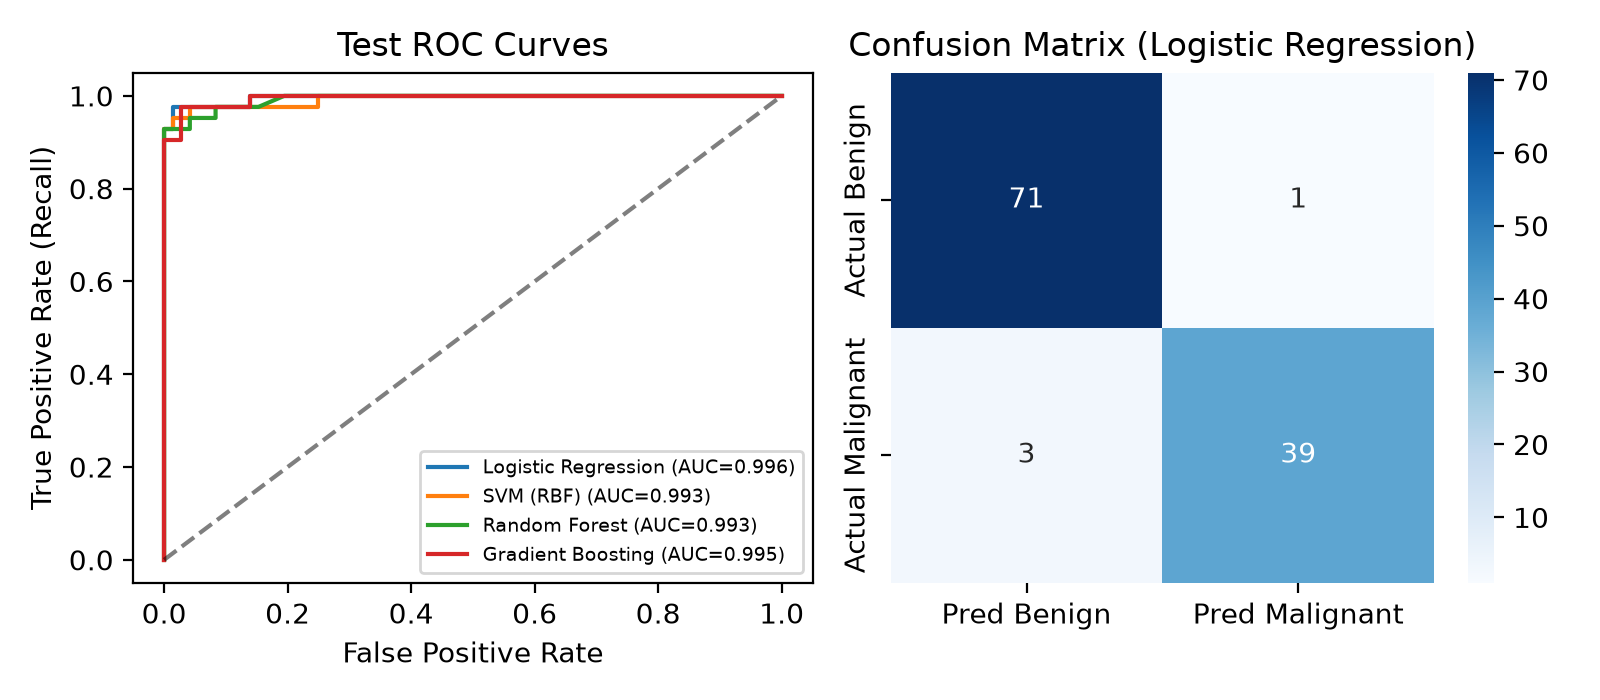

In [8]:
# ROC Curve and Confusion Matrix
plt.show()